# Task 2 - Recommendation System Development

This notebook develops recommendation-system analysis for the Commercial Director scenario, focusing on customer value, product performance and purchase behaviour.

## 1. Import the required libraries

Pandas and NumPy support data preparation. Matplotlib and Seaborn are included for later charts, and Scikit-Learn's cosine similarity will support a collaborative recommendation approach.

In [35]:
# Import libraries for tables, calculations and charts.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Import cosine similarity for a later collaborative-filtering recommender.
from sklearn.metrics.pairwise import cosine_similarity

## 2. Load the allocated datasets

Load the assigned customer, product and transaction CSV files from the `Datasets` folder. Keeping these as separate DataFrames makes each source easier to inspect before joining.

In [36]:
# Set paths to the three allocated CSV files.
customers_path = "../Datasets/Customers_members.csv"
products_path = "../Datasets/Products_overview.csv"
transactions_path = "../Datasets/Transactions_history.csv"

try:
    # Load each source dataset into its own DataFrame.
    customers_raw = pd.read_csv(customers_path)
    products_raw = pd.read_csv(products_path)
    transactions_raw = pd.read_csv(transactions_path)
    print("Customer, product and transaction datasets loaded successfully.")
except FileNotFoundError as error:
    print(f"A dataset file could not be found: {error.filename}")
    print("Check the CSV filenames and confirm that the notebook is in the Ca1-folder directory.")

Customer, product and transaction datasets loaded successfully.


## 3. Inspect the source datasets

Check each dataset's dimensions, sample rows, column names and data types before combining them. This helps confirm the join keys and the meaning of the transaction measures.

In [37]:
# Display dataset dimensions and the first five rows for each source.
for dataset_name, dataset in {
    "Customers": customers_raw,
    "Products": products_raw,
    "Transactions": transactions_raw
}.items():
    print(f"{dataset_name} dataset shape: {dataset.shape}")
    display(dataset.head())

# Inspect column names, data types and non-null counts.
print("Customers dataset information:")
customers_raw.info()

print("Products dataset information:")
products_raw.info()

print("Transactions dataset information:")
transactions_raw.info()

Customers dataset shape: (1000, 5)


,CustomerID,AgeGroup,Region,LoyaltyLevel,MembershipYears
0,1,36-50,East,Bronze,9
1,2,26-35,East,Bronze,4
2,3,18-25,East,Silver,10
3,4,36-50,East,Bronze,14
4,5,26-35,North,Bronze,7


Products dataset shape: (200, 6)


,ProductID,Category,Brand,Price,Rating,PopularityScore
0,1,Electronics,TechMax,474.45,4.54,3
1,2,Gaming,SmartBuy,285.11,3.16,2
2,3,books,HomePro,370.79,3.01,1
3,4,Home,TechMax,416.38,3.38,1
4,5,Books,TechMax,62.37,3.42,1


Transactions dataset shape: (19166, 5)


,CustomerID,ProductID,PurchaseCount,LastPurchaseDays,Spend
0,1,82,3,162,104.01
1,2,7,4,276,387.48
2,3,170,4,215,1507.40
3,3,9,1,251,341.40
4,4,64,3,354,1250.40


Customers dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   CustomerID       1000 non-null   int64
 1   AgeGroup         1000 non-null   str  
 2   Region           1000 non-null   str  
 3   LoyaltyLevel     1000 non-null   str  
 4   MembershipYears  1000 non-null   int64
dtypes: int64(2), str(3)
memory usage: 39.2 KB
Products dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ProductID        200 non-null    int64  
 1   Category         200 non-null    str    
 2   Brand            200 non-null    str    
 3   Price            200 non-null    float64
 4   Rating           185 non-null    float64
 5   PopularityScore  200 non-null    int64  
dtypes: float64(2), int64(2),

## 4. Assess data quality and key integrity

Summarise missing values, exact duplicate rows and duplicate entity keys. Transaction duplicates are reported for review rather than removed automatically because the file has no transaction ID to distinguish accidental duplicates from repeated purchases.

In [38]:
# Summarise missing cells and fully duplicated rows in each source dataset.
data_quality_summary = pd.DataFrame({
    "Missing Cells": [
        customers_raw.isnull().sum().sum(),
        products_raw.isnull().sum().sum(),
        transactions_raw.isnull().sum().sum()
    ],
    "Exact Duplicate Rows": [
        customers_raw.duplicated().sum(),
        products_raw.duplicated().sum(),
        transactions_raw.duplicated().sum()
    ]
}, index=["Customers", "Products", "Transactions"])

# Show missing counts by field to identify which columns need attention.
missing_by_column = pd.concat({
    "Customers": customers_raw.isnull().sum(),
    "Products": products_raw.isnull().sum(),
    "Transactions": transactions_raw.isnull().sum()
}, names=["Dataset", "Column"]).to_frame(name="Missing Values")

missing_by_column["Missing Percentage"] = pd.concat({
    "Customers": customers_raw.isnull().mean() * 100,
    "Products": products_raw.isnull().mean() * 100,
    "Transactions": transactions_raw.isnull().mean() * 100
}, names=["Dataset", "Column"])

print("Dataset-level quality summary:")
display(data_quality_summary)

print("Missing values by column:")
display(missing_by_column)

Dataset-level quality summary:


,Missing Cells,Exact Duplicate Rows
Customers,0,0
Products,15,0
Transactions,0,384


Missing values by column:


Missing Values  Missing Percentage
Dataset      Column                                              
Customers    CustomerID                     0                 0.0
             AgeGroup                       0                 0.0
             Region                         0                 0.0
             LoyaltyLevel                   0                 0.0
             MembershipYears                0                 0.0
Products     ProductID                      0                 0.0
             Category                       0                 0.0
             Brand                          0                 0.0
             Price                          0                 0.0
             Rating                        15                 7.5
             PopularityScore                0                 0.0
Transactions CustomerID                     0                 0.0
             ProductID                      0                 0.0
             PurchaseCount                  0                 0.0
             LastPurchaseDays               0                 0.0
             Spend                          0                 0.0

In [39]:
# Check whether the entity keys are unique in their respective datasets.
key_duplicate_summary = pd.Series({
    "Duplicate CustomerID values": customers_raw["CustomerID"].duplicated().sum(),
    "Duplicate ProductID values": products_raw["ProductID"].duplicated().sum()
}, name="Duplicate key count")

print("Duplicate entity keys:")
display(key_duplicate_summary)

# Check that each transaction references an existing customer and product.
unmatched_customer_count = (~transactions_raw["CustomerID"].isin(customers_raw["CustomerID"])).sum()
unmatched_product_count = (~transactions_raw["ProductID"].isin(products_raw["ProductID"])).sum()

print(f"Transactions with an unknown CustomerID: {unmatched_customer_count}")
print(f"Transactions with an unknown ProductID: {unmatched_product_count}")

Duplicate entity keys:


Duplicate CustomerID values    0
Duplicate ProductID values     0
Name: Duplicate key count, dtype: int64

Transactions with an unknown CustomerID: 0
Transactions with an unknown ProductID: 0


## 5. Integrate the datasets

Create clean working copies, standardize product category capitalization, then enrich transaction records with customer and product details. The join validation checks that each transaction links to one customer and one product.

In [40]:
# Create working copies and standardize category labels for consistent grouping.
customers = customers_raw.copy()
products = products_raw.copy()
transactions = transactions_raw.copy()

products["Category"] = products["Category"].str.strip().str.title()

# Add customer and product details to each transaction.
transactions_enriched = transactions.merge(
    customers,
    on="CustomerID",
    how="left",
    validate="many_to_one"
).merge(
    products,
    on="ProductID",
    how="left",
    validate="many_to_one"
)

print(f"Transactions before integration: {len(transactions)}")
print(f"Transactions after integration: {len(transactions_enriched)}")
print(f"Integrated dataset shape: {transactions_enriched.shape}")
display(transactions_enriched.head())

Transactions before integration: 19166
Transactions after integration: 19166
Integrated dataset shape: (19166, 14)


,CustomerID,ProductID,PurchaseCount,LastPurchaseDays,Spend,AgeGroup,Region,LoyaltyLevel,MembershipYears,Category,Brand,Price,Rating,PopularityScore
0,1,82,3,162,104.01,36-50,East,Bronze,9,Books,HomePro,34.67,3.56,5
1,2,7,4,276,387.48,26-35,East,Bronze,4,Home,SmartBuy,96.87,3.79,49
2,3,170,4,215,1507.40,18-25,East,Silver,10,Kitchen,FitLife,376.85,2.78,4
3,3,9,1,251,341.40,18-25,East,Silver,10,Gaming,SmartBuy,341.40,4.23,3
4,4,64,3,354,1250.40,36-50,East,Bronze,14,Gaming,TechMax,416.80,NaN,1


## 6. Create the customer-product interaction matrix

The matrix aggregates `PurchaseCount` for each customer-product pair. A zero means no recorded purchase interaction in the transaction data. A second matrix sums `Spend` for later customer-value analysis.

In [41]:
# Aggregate repeated customer-product records into total purchase counts.
interaction_matrix = transactions.pivot_table(
    index="CustomerID",
    columns="ProductID",
    values="PurchaseCount",
    aggfunc="sum",
    fill_value=0
)

# Retain a spend matrix for customer and product value analysis.
spend_matrix = transactions.pivot_table(
    index="CustomerID",
    columns="ProductID",
    values="Spend",
    aggfunc="sum",
    fill_value=0
)

print(f"Interaction matrix shape (customers, products): {interaction_matrix.shape}")
print(f"Number of recorded customer-product interactions: {(interaction_matrix > 0).sum().sum()}")
display(interaction_matrix.head())

Interaction matrix shape (customers, products): (1000, 200)
Number of recorded customer-product interactions: 15692


ProductID,1,2,3,4,5,6,7,8,9,10,...,191,192,193,194,195,196,197,198,199,200
CustomerID,,,,,,,,,,,,,,,,,,,,,
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,4,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## 7. Customer Analytics

This section summarizes customer spending and purchase frequency for the Commercial Director scenario. The transaction file contains 384 exact duplicate rows and no transaction ID, so the rankings below use all supplied rows and should be treated as provisional until those repeats are confirmed.

### 7.1 Build customer purchase summaries

Aggregate each customer's spend and purchase count, and add product breadth and profile details. Here, purchase frequency means the sum of `PurchaseCount`, not the number of dataset rows.

In [42]:
# Aggregate transaction measures for each customer.
customer_purchase_summary = (
    transactions_enriched.groupby("CustomerID")
    .agg(
        TotalSpend=("Spend", "sum"),
        TotalPurchases=("PurchaseCount", "sum"),
        TransactionRows=("ProductID", "size"),
        UniqueProducts=("ProductID", "nunique"),
        MostRecentPurchaseDays=("LastPurchaseDays", "min")
    )
    .reset_index()
)

# Add customer profile details for segment comparisons.
customer_purchase_summary = customer_purchase_summary.merge(
    customers[["CustomerID", "AgeGroup", "Region", "LoyaltyLevel", "MembershipYears"]],
    on="CustomerID",
    how="left",
    validate="one_to_one"
)

# Calculate average spend per recorded purchase unit.
customer_purchase_summary["AverageSpendPerPurchase"] = (
    customer_purchase_summary["TotalSpend"]
    / customer_purchase_summary["TotalPurchases"].replace(0, np.nan)
)

customer_purchase_summary.head()

,CustomerID,TotalSpend,TotalPurchases,TransactionRows,UniqueProducts,MostRecentPurchaseDays,AgeGroup,Region,LoyaltyLevel,MembershipYears,AverageSpendPerPurchase
0,1,104.01,3,1,1,162,36-50,East,Bronze,9,34.67
1,2,387.48,4,1,1,276,26-35,East,Bronze,4,96.87
2,3,1848.80,5,2,2,215,18-25,East,Silver,10,369.76
3,4,3469.52,8,3,2,242,36-50,East,Bronze,14,433.69
4,5,331.78,2,1,1,23,26-35,North,Bronze,7,165.89


### 7.2 Top 10 customers by spend and purchase frequency

These rankings show the customers with the highest recorded total spend and purchase counts. Keeping the measures separate avoids treating high spend and frequent purchasing as the same behaviour.

In [43]:
# Select columns that make the customer rankings easy to interpret.
customer_ranking_columns = [
    "CustomerID",
    "Region",
    "LoyaltyLevel",
    "TotalSpend",
    "TotalPurchases",
    "UniqueProducts"
]

# Rank customers by total spend.
top_10_customers_by_spend = (
    customer_purchase_summary.nlargest(10, "TotalSpend")
    [customer_ranking_columns]
    .reset_index(drop=True)
)

# Rank customers by total purchase count.
top_10_customers_by_frequency = (
    customer_purchase_summary.nlargest(10, "TotalPurchases")
    [customer_ranking_columns]
    .reset_index(drop=True)
)

print("Top 10 customers by total recorded spend:")
display(top_10_customers_by_spend)

print("Top 10 customers by total purchase frequency:")
display(top_10_customers_by_frequency)

Top 10 customers by total recorded spend:


,CustomerID,Region,LoyaltyLevel,TotalSpend,TotalPurchases,UniqueProducts
0,395,East,Bronze,27323.95,86,23
1,751,West,Gold,23084.09,72,19
2,550,East,Silver,23065.13,87,25
3,999,East,Silver,23012.88,72,19
4,298,West,Bronze,22883.98,76,22
5,454,East,Silver,22750.97,76,20
6,57,West,Bronze,22713.06,71,24
7,355,South,Gold,22533.65,79,22
8,546,North,Silver,22399.85,79,24
9,676,North,Silver,22273.50,71,23


Top 10 customers by total purchase frequency:


,CustomerID,Region,LoyaltyLevel,TotalSpend,TotalPurchases,UniqueProducts
0,550,East,Silver,23065.13,87,25
1,395,East,Bronze,27323.95,86,23
2,664,West,Bronze,20840.02,84,22
3,290,North,Bronze,22138.19,83,27
4,831,West,Bronze,19476.28,83,26
5,812,West,Gold,20100.33,81,22
6,879,East,Bronze,21698.92,81,24
7,289,West,Silver,20071.17,80,20
8,480,West,Bronze,20891.12,80,24
9,571,South,Bronze,17691.76,80,19


### 7.3 Customer value analysis

Use total-spend percentiles to describe high-, medium- and low-spend customer groups. Compare average spend, purchase count, product breadth and days since most recent purchase, plus the high-spend group's loyalty and regional mix.

In [44]:
# Assign descriptive spend tiers using each customer's percentile rank.
spend_percentile = customer_purchase_summary["TotalSpend"].rank(pct=True)
customer_purchase_summary["CustomerValueTier"] = np.select(
    [spend_percentile >= 0.75, spend_percentile >= 0.25],
    ["High", "Medium"],
    default="Low"
)

# Compare purchasing behaviour across spend-based value tiers.
customer_value_analysis = (
    customer_purchase_summary.groupby("CustomerValueTier")
    .agg(
        CustomerCount=("CustomerID", "nunique"),
        AverageTotalSpend=("TotalSpend", "mean"),
        AveragePurchaseCount=("TotalPurchases", "mean"),
        AverageUniqueProducts=("UniqueProducts", "mean"),
        AverageDaysSinceLastPurchase=("MostRecentPurchaseDays", "mean")
    )
    .reindex(["High", "Medium", "Low"])
)

# Profile high-spend customers by loyalty level and region.
high_value_customer_profile = (
    customer_purchase_summary[customer_purchase_summary["CustomerValueTier"] == "High"]
    .groupby(["Region", "LoyaltyLevel"])
    .agg(
        CustomerCount=("CustomerID", "nunique"),
        AverageTotalSpend=("TotalSpend", "mean"),
        AveragePurchaseCount=("TotalPurchases", "mean")
    )
    .sort_values("AverageTotalSpend", ascending=False)
)

print("Customer value summary by spend tier:")
display(customer_value_analysis)

print("High-spend customer profile by region and loyalty level:")
display(high_value_customer_profile.head(10))

Customer value summary by spend tier:


,CustomerCount,AverageTotalSpend,AveragePurchaseCount,AverageUniqueProducts,AverageDaysSinceLastPurchase
CustomerValueTier,,,,,
High,251,17953.555777,67.390438,20.561753,14.039841
Medium,500,11695.504480,49.276000,16.356000,19.282000
Low,249,5533.945382,25.554217,9.449799,50.473896


High-spend customer profile by region and loyalty level:


,,CustomerCount,AverageTotalSpend,AveragePurchaseCount
Region,LoyaltyLevel,,,
East,Bronze,29,18322.112759,68.620690
West,Gold,14,18303.992857,67.500000
East,Silver,21,18282.746190,69.190476
North,Silver,17,18258.088824,66.941176
West,Silver,16,18104.221250,69.000000
North,Bronze,36,18058.345000,68.555556
East,Gold,9,17970.122222,62.333333
South,Bronze,27,17785.996296,68.740741
West,Bronze,41,17768.066341,66.219512


## 8. Product Analytics

This section evaluates product performance using transaction `Spend` as recorded revenue and `PurchaseCount` as purchase volume. Product revenue totals include all supplied transaction rows, including the 384 exact duplicates flagged in the data-quality check, so treat totals as provisional until those repeats are confirmed.

### 8.1 Product-level performance

Aggregate revenue and purchase counts by product, and retain ratings and popularity scores as context for product performance.

In [45]:
# Summarise each product's observed revenue, purchase count and available product attributes.
product_performance = (
    transactions_enriched.groupby(
        ["ProductID", "Category", "Brand"],
        dropna=False
    )
    .agg(
        TotalRevenue=("Spend", "sum"),
        TotalPurchaseCount=("PurchaseCount", "sum"),
        TransactionRows=("CustomerID", "size"),
        AverageRating=("Rating", "mean"),
        AverageListedPrice=("Price", "mean"),
        AveragePopularityScore=("PopularityScore", "mean")
    )
    .reset_index()
    .sort_values("TotalRevenue", ascending=False)
)

product_performance.head()

,ProductID,Category,Brand,TotalRevenue,TotalPurchaseCount,TransactionRows,AverageRating,AverageListedPrice,AveragePopularityScore
101,102,Books,FitLife,1756773.72,3627,1424,2.88,484.36,38.0
6,7,Home,SmartBuy,488127.93,5039,1994,3.79,96.87,49.0
40,41,Home,HomePro,446687.43,1097,454,NaN,407.19,12.0
133,134,Kitchen,SmartBuy,415775.14,1397,553,3.44,297.62,14.0
7,8,Home,HomePro,240130.74,703,270,3.71,341.58,6.0


### 8.2 Top 10 products by revenue

Rank products by recorded spend and display purchase volume and average rating to provide additional context beyond revenue alone.

In [46]:
# Display the ten products with the highest recorded revenue.
top_10_products_by_revenue = (
    product_performance[
        [
            "ProductID",
            "Category",
            "Brand",
            "TotalRevenue",
            "TotalPurchaseCount",
            "AverageRating"
        ]
    ]
    .head(10)
    .reset_index(drop=True)
)

top_10_products_by_revenue

,ProductID,Category,Brand,TotalRevenue,TotalPurchaseCount,AverageRating
0,102,Books,FitLife,1756773.72,3627,2.88
1,7,Home,SmartBuy,488127.93,5039,3.79
2,41,Home,HomePro,446687.43,1097,NaN
3,134,Kitchen,SmartBuy,415775.14,1397,3.44
4,8,Home,HomePro,240130.74,703,3.71
5,184,Fitness,SmartBuy,195388.13,973,4.36
6,45,Kitchen,NextGen,190771.02,418,3.86
7,65,Kitchen,TechMax,187267.92,498,3.19
8,81,Home,FitLife,182543.45,445,4.38
9,137,Electronics,NextGen,172986.45,377,3.06


### 8.3 Revenue by category and brand

These summaries compare category and brand revenue, purchase counts and each group's share of observed spend.

In [47]:
# Group product performance by category.
revenue_by_category = (
    transactions_enriched.groupby("Category", dropna=False)
    .agg(
        TotalRevenue=("Spend", "sum"),
        TotalPurchaseCount=("PurchaseCount", "sum"),
        Products=("ProductID", "nunique")
    )
    .sort_values("TotalRevenue", ascending=False)
)
revenue_by_category["RevenueSharePercent"] = (
    revenue_by_category["TotalRevenue"]
    / revenue_by_category["TotalRevenue"].sum()
    * 100
)

# Group product performance by brand.
revenue_by_brand = (
    transactions_enriched.groupby("Brand", dropna=False)
    .agg(
        TotalRevenue=("Spend", "sum"),
        TotalPurchaseCount=("PurchaseCount", "sum"),
        Products=("ProductID", "nunique")
    )
    .sort_values("TotalRevenue", ascending=False)
)
revenue_by_brand["RevenueSharePercent"] = (
    revenue_by_brand["TotalRevenue"]
    / revenue_by_brand["TotalRevenue"].sum()
    * 100
)

print("Revenue by product category:")
display(revenue_by_category)

print("Revenue by brand:")
display(revenue_by_brand)

# Summarise the leading category and brand by recorded revenue.
print(f"Highest-revenue category: {revenue_by_category.index[0]}")
print(f"Highest-revenue brand: {revenue_by_brand.index[0]}")

Revenue by product category:


,TotalRevenue,TotalPurchaseCount,Products,RevenueSharePercent
Category,,,,
Books,2795746.40,8933,37,23.829996
Home,2337945.87,11719,30,19.927859
Kitchen,1808430.27,6584,26,15.414448
Electronics,1796995.49,8811,38,15.316981
Fitness,1581412.97,6327,34,13.479429
Gaming,1411516.14,5542,35,12.031286


Revenue by brand:


,TotalRevenue,TotalPurchaseCount,Products,RevenueSharePercent
Brand,,,,
FitLife,3348546.16,9829,33,28.541874
SmartBuy,2632371.13,14441,41,22.437441
HomePro,1911437.37,7894,33,16.292445
TechMax,1620948.69,5768,35,13.816418
NextGen,1306117.89,4748,29,11.132907
PrimeGoods,912625.90,5236,29,7.778914


Highest-revenue category: Books
Highest-revenue brand: FitLife


## 9. GroupBy and Pivot Table Analysis

This section compares recorded spend and purchase behaviour across customer segments and product categories. Spend totals include the 384 exact duplicate transaction rows flagged earlier, so treat them as provisional.

### 9.1 GroupBy analyses

Three segment views: customer region, loyalty level and age group.

In [48]:
# Compare spend and purchasing behaviour across customer segments.
def summarise_segment(column):
    summary = (
        transactions_enriched.groupby(column)
        .agg(
            Customers=("CustomerID", "nunique"),
            TotalSpend=("Spend", "sum"),
            TotalPurchases=("PurchaseCount", "sum"),
            AverageSpendPerRow=("Spend", "mean")
        )
        .sort_values("TotalSpend", ascending=False)
    )
    summary["SpendPerCustomer"] = summary["TotalSpend"] / summary["Customers"]
    return summary

spend_by_region = summarise_segment("Region")
spend_by_loyalty = summarise_segment("LoyaltyLevel")
spend_by_age_group = summarise_segment("AgeGroup")

print("GroupBy 1: spend by customer region")
display(spend_by_region)

print("GroupBy 2: spend by loyalty level")
display(spend_by_loyalty)

print("GroupBy 3: spend by age group")
display(spend_by_age_group)

GroupBy 1: spend by customer region


,Customers,TotalSpend,TotalPurchases,AverageSpendPerRow,SpendPerCustomer
Region,,,,,
West,255,3055425.58,12428,615.764929,11982.061098
South,254,2919495.62,11982,609.625312,11494.077244
East,253,2881880.28,11734,615.786385,11390.831146
North,238,2875245.66,11772,607.232452,12080.864118


GroupBy 2: spend by loyalty level


,Customers,TotalSpend,TotalPurchases,AverageSpendPerRow,SpendPerCustomer
LoyaltyLevel,,,,,
Bronze,493,5922081.38,24239,612.734752,12012.335456
Silver,288,3352761.26,13644,613.833991,11641.532153
Gold,219,2457204.50,10033,608.369522,11220.111872


GroupBy 3: spend by age group


,Customers,TotalSpend,TotalPurchases,AverageSpendPerRow,SpendPerCustomer
AgeGroup,,,,,
18-25,263,3159311.37,12755,621.055901,12012.590760
50+,266,3131204.13,12877,605.531644,11771.444098
26-35,248,2980951.36,12155,613.490710,12019.965161
36-50,223,2460580.28,10129,607.700736,11033.992287


### 9.2 Pivot tables

Pivot table 1 shows total spend by product category and loyalty level. Pivot table 2 shows average spend per transaction row by customer region and category.

In [49]:
# Pivot table 1: total spend by category and loyalty level.
pivot_category_loyalty = pd.pivot_table(
    transactions_enriched,
    values="Spend",
    index="Category",
    columns="LoyaltyLevel",
    aggfunc="sum",
    fill_value=0,
    margins=True,
    margins_name="Total"
)

# Pivot table 2: average spend per transaction row by region and category.
pivot_region_category = pd.pivot_table(
    transactions_enriched,
    values="Spend",
    index="Region",
    columns="Category",
    aggfunc="mean",
    fill_value=0
)

print("Pivot table 1: total spend by category and loyalty level")
display(pivot_category_loyalty.round(2))

print("Pivot table 2: average spend per row by region and category")
display(pivot_region_category.round(2))

# Report the strongest cell in each pivot table.
loyalty_pivot_body = pivot_category_loyalty.drop(index="Total", columns="Total")
top_category, top_loyalty = loyalty_pivot_body.stack().idxmax()
top_region, top_region_category = pivot_region_category.stack().idxmax()

print(f"Highest total spend: {top_category} / {top_loyalty}")
print(f"Highest average spend per row: {top_region} / {top_region_category}")

Pivot table 1: total spend by category and loyalty level


LoyaltyLevel,Bronze,Gold,Silver,Total
Category,,,,
Books,1408349.96,590850.02,796546.42,2795746.40
Electronics,918225.77,363469.71,515300.01,1796995.49
Fitness,769769.49,352025.64,459617.84,1581412.97
Gaming,731662.61,281576.28,398277.25,1411516.14
Home,1184942.10,495214.79,657788.98,2337945.87
Kitchen,909131.45,374068.06,525230.76,1808430.27
Total,5922081.38,2457204.50,3352761.26,11732047.14


Pivot table 2: average spend per row by region and category


Category,Books,Electronics,Fitness,Gaming,Home,Kitchen
Region,,,,,,
East,773.91,527.81,608.52,613.29,526.17,673.36
North,787.30,502.05,632.19,643.47,478.63,687.50
South,797.16,489.94,597.14,637.63,517.65,672.63
West,814.48,530.83,642.88,618.78,488.26,660.61


Highest total spend: Books / Bronze
Highest average spend per row: West / Books


## 10. Recommendation System Development

Two recommenders are built from the customer-product interaction matrix:

1. **Popularity-based:** recommends the products bought by the most distinct customers that the target customer has not yet bought. It needs no personal history, so it is a simple baseline and a fallback for new customers.
2. **Item-based collaborative filtering:** recommends products whose purchase patterns are similar (cosine similarity) to the products the customer already buys. It personalises recommendations and works well when there are more customers than products.

Popularity counts distinct buyers rather than purchase counts, so duplicate transaction rows cannot inflate it.

### 10.1 Popularity-based recommender

In [50]:
product_lookup = products.set_index("ProductID")[["Category", "Brand"]]

def add_product_details(scores, score_name):
    """Return recommended products with category and brand beside the score."""
    return scores.rename(score_name).to_frame().join(product_lookup).reset_index()

def recommend_popular(customer_id, matrix=interaction_matrix, n=5):
    """Top-n most widely bought products the customer has not bought."""
    already_bought = matrix.columns[matrix.loc[customer_id] > 0]
    buyers_per_product = (matrix > 0).sum().drop(already_bought)
    return buyers_per_product.nlargest(n)

print(f"Most widely bought products overall:")
display(add_product_details((interaction_matrix > 0).sum().nlargest(5), "DistinctBuyers"))

Most widely bought products overall:


,ProductID,DistinctBuyers,Category,Brand
0,7,824,Home,SmartBuy
1,102,699,Books,FitLife
2,13,517,Electronics,SmartBuy
3,134,414,Kitchen,SmartBuy
4,41,362,Home,HomePro


### 10.2 Item-based collaborative filtering

Cosine similarity compares each pair of products by the customers who bought them. A product's score for a customer is the sum of its similarity to every product that customer has bought, weighted by purchase count. Products already bought are excluded.

In [51]:
def build_item_similarity(matrix):
    """Product-by-product cosine similarity from customer purchase patterns."""
    similarity = cosine_similarity(matrix.T)
    return pd.DataFrame(similarity, index=matrix.columns, columns=matrix.columns)

def recommend_item_based(customer_id, matrix=interaction_matrix, similarity=None, n=5):
    """Top-n products most similar to the customer's purchases, excluding owned ones."""
    if similarity is None:
        similarity = item_similarity
    purchases = matrix.loc[customer_id]
    scores = similarity.dot(purchases)
    return scores.drop(purchases[purchases > 0].index).nlargest(n)

item_similarity = build_item_similarity(interaction_matrix)
print(f"Item similarity matrix shape: {item_similarity.shape}")

Item similarity matrix shape: (200, 200)


### 10.3 Example recommendations

Both recommenders are shown for five example customers, to confirm they run and to see how the lists differ. Formal evaluation is the next step.

In [52]:
example_customers = interaction_matrix.index[:5]

for customer_id in example_customers:
    print(f"Customer {customer_id}")
    print("Popularity-based recommendations:")
    display(add_product_details(recommend_popular(customer_id), "DistinctBuyers"))
    print("Item-based collaborative filtering recommendations:")
    display(add_product_details(recommend_item_based(customer_id), "SimilarityScore"))

Customer 1
Popularity-based recommendations:


,ProductID,DistinctBuyers,Category,Brand
0,7,824,Home,SmartBuy
1,102,699,Books,FitLife
2,13,517,Electronics,SmartBuy
3,134,414,Kitchen,SmartBuy
4,41,362,Home,HomePro


Item-based collaborative filtering recommendations:


,ProductID,SimilarityScore,Category,Brand
0,7,0.865330,Home,SmartBuy
1,102,0.706111,Books,FitLife
2,41,0.653844,Home,HomePro
3,13,0.604712,Electronics,SmartBuy
4,137,0.533933,Electronics,NextGen


Customer 2
Popularity-based recommendations:


,ProductID,DistinctBuyers,Category,Brand
0,102,699,Books,FitLife
1,13,517,Electronics,SmartBuy
2,134,414,Kitchen,SmartBuy
3,41,362,Home,HomePro
4,184,306,Fitness,SmartBuy


... (10 outputs left out)

Customer 5
Popularity-based recommendations:


,ProductID,DistinctBuyers,Category,Brand
0,7,824,Home,SmartBuy
1,102,699,Books,FitLife
2,13,517,Electronics,SmartBuy
3,134,414,Kitchen,SmartBuy
4,41,362,Home,HomePro


Item-based collaborative filtering recommendations:


,ProductID,SimilarityScore,Category,Brand
0,102,0.517705,Books,FitLife
1,7,0.456193,Home,SmartBuy
2,41,0.412311,Home,HomePro
3,13,0.393681,Electronics,SmartBuy
4,119,0.381263,Gaming,NextGen


## 11. Recommendation Evaluation

The two recommenders are compared with a leave-one-out test:

1. For every customer with at least two purchased products, one purchased product is hidden at random.
2. Each recommender is rebuilt from the remaining purchases and produces a top-10 list of products the customer has not bought.
3. A recommendation is a **hit** if the hidden product appears in the list.

The test is repeated over five random splits, and a random recommender is included as a reference point. Metrics:

- **HitRate@k:** share of customers whose hidden product is in the top k. With one hidden product, this equals recall@k.
- **MRR@10:** mean reciprocal rank of the hidden product (1 for rank 1, 0.5 for rank 2, 0 if not in the top 10).

This is an offline test of how well each method recovers past purchases. It does not measure the sales uplift of showing a recommendation. Popularity uses distinct buyers, so the 384 duplicate transaction rows do not affect it. Item-based CF uses purchase counts, so duplicates could slightly affect its scores.

### 11.1 Run the evaluation

In [ ]:
N_SPLITS = 5
values = interaction_matrix.to_numpy()

# Customers need a second product so something remains to learn from after hiding one.
eligible_rows = np.flatnonzero((values > 0).sum(axis=1) >= 2)

def run_holdout(seed):
    """Hide one purchase per eligible customer; return the hidden product and each method's ranking."""
    rng = np.random.default_rng(seed)
    train = values.copy()
    hidden = np.array([rng.choice(np.flatnonzero(values[r] > 0)) for r in eligible_rows])
    train[eligible_rows, hidden] = 0

    scores = {
        "Random": rng.random(train.shape),
        "Popularity": np.tile((train > 0).sum(axis=0), (len(train), 1)),
        "Item-based CF": train @ cosine_similarity(train.T),
    }
    # Owned products sink to the bottom so only unbought products are recommended.
    orders = {
        method: np.argsort(-np.where(train > 0, -np.inf, s)[eligible_rows], axis=1, kind="stable")
        for method, s in scores.items()
    }
    return hidden, orders

def hidden_rank(order, hidden):
    return np.argmax(order == hidden[:, None], axis=1) + 1

results = []
for split in range(N_SPLITS):
    hidden, orders = run_holdout(split)
    for method, order in orders.items():
        ranks = hidden_rank(order, hidden)
        results.append({
            "Split": split,
            "Method": method,
            "HitRate@5": (ranks <= 5).mean(),
            "HitRate@10": (ranks <= 10).mean(),
            "MRR@10": np.where(ranks <= 10, 1 / ranks, 0).mean(),
        })

evaluation_results = pd.DataFrame(results)
metric_columns = ["HitRate@5", "HitRate@10", "MRR@10"]

evaluation_summary = (
    evaluation_results.groupby("Method")[metric_columns].mean()
    .sort_values("HitRate@10", ascending=False)
)
evaluation_std = evaluation_results.groupby("Method")[metric_columns].std().loc[evaluation_summary.index]

print(f"Customers evaluated: {len(eligible_rows)} of {len(values)}")
print(f"Mean over {N_SPLITS} random hold-out splits:")
display(evaluation_summary.round(4))

print("Standard deviation across splits:")
display(evaluation_std.round(4))

leader, runner_up = evaluation_summary.index[:2]
gap = evaluation_summary.loc[leader, "HitRate@10"] - evaluation_summary.loc[runner_up, "HitRate@10"]
spread = evaluation_std.loc[[leader, runner_up], "HitRate@10"].max()
print(f"Highest HitRate@10: {leader}, ahead of {runner_up} by {gap:.4f}")
print("Gap is within split-to-split variation: treat the two as tied." if gap < spread
      else "Gap is larger than split-to-split variation.")

Customers evaluated: 971 of 1000
Mean over 5 random hold-out splits:


,HitRate@5,HitRate@10,MRR@10
Method,,,
Item-based CF,0.2579,0.3372,0.1882
Popularity,0.2583,0.3364,0.1898
Random,0.0257,0.0544,0.0161


Standard deviation across splits:


,HitRate@5,HitRate@10,MRR@10
Method,,,
Item-based CF,0.0152,0.0131,0.0092
Popularity,0.0129,0.0140,0.0084
Random,0.0035,0.0034,0.0031


Highest HitRate@10: Item-based CF (0.337)


### 11.2 Compare the methods

The chart shows each method's mean hit rate, with error bars for the spread across the five splits. The table that follows shows, for five example customers, the product that was hidden and the rank each method gave it (a rank above 10 means it was not recommended).

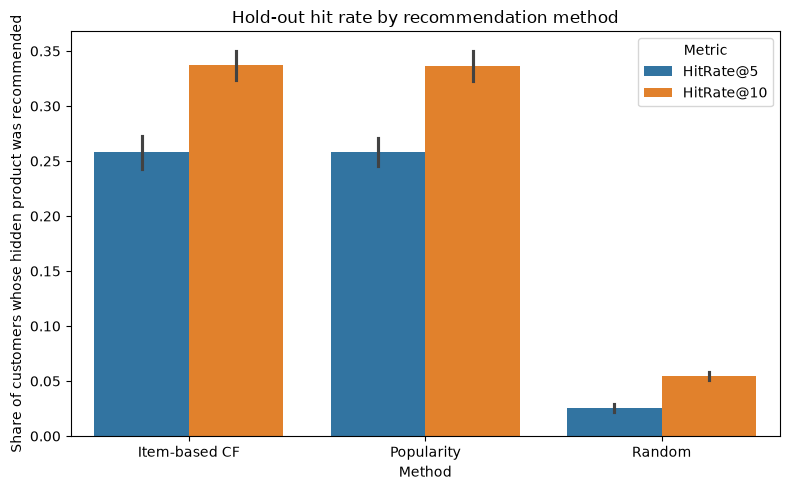

,HiddenProductID,Random,Popularity,Item-based CF
CustomerID,,,,
3,170,27,22,7
4,102,129,2,9
7,127,8,197,194
9,47,105,153,107
10,56,178,49,30


In [54]:
hit_rate_plot = evaluation_results.melt(
    id_vars=["Method"], value_vars=["HitRate@5", "HitRate@10"],
    var_name="Metric", value_name="Hit rate",
)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=hit_rate_plot, x="Method", y="Hit rate", hue="Metric",
    order=evaluation_summary.index, errorbar="sd",
)
plt.title("Hold-out hit rate by recommendation method")
plt.xlabel("Method")
plt.ylabel("Share of customers whose hidden product was recommended")
plt.tight_layout()
plt.show()

# Rank each method gave the hidden product, for five example customers (split 0).
hidden, orders = run_holdout(0)
example_positions = range(5)
example_ranks = pd.DataFrame(
    {method: hidden_rank(order, hidden)[list(example_positions)] for method, order in orders.items()},
    index=pd.Index(interaction_matrix.index[eligible_rows][list(example_positions)], name="CustomerID"),
)
example_ranks.insert(0, "HiddenProductID", interaction_matrix.columns[hidden[list(example_positions)]])
display(example_ranks)